<a href="https://colab.research.google.com/github/Alejandra300905/NLP_Polarity_of_film_reviews_and_the_problem_of_negation/blob/main/ProyectoClasificacionR_AlejandraB_CarlosM_NathalieL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# R3.1 Polaridad de reseñas de cine y el problema de la negación

### Bitácora de Contribuciones del Equipo

| Etapa | Programó (Implementación) | Revisó (Código y Resultados) | Hizo la Presentación |
| :---: | :--- | :--- | :--- |
| **Etapa 1** | Carlos | Alejandra | Nathalie |
| **Etapa 2** | Alejandra | Nathalie | Carlos |
| **Etapa 3** | Nathalie | Carlos | Alejandra |


### Etapa 1 - **Análisis, representacion y baseline.** Limpieza (etiquetas HTML, puntuación) y división Train, Dev y Test. Baseline: bolsa de palabras de unigramas + Bayes ingenuo

In [1]:
import os
import tarfile
import pandas as pd
from google.colab import files

tar_filename = 'aclImdb_v1.tar.gz'

# Si no existe la carpeta extraída, procedemos a obtener el archivo
if not os.path.exists('aclImdb'):
    if not os.path.exists(tar_filename):
        print("Por favor, sube tu archivo aclImdb_v1.tar.gz:")
        uploaded = files.upload()
        # Renombrar en caso de que se haya subido con otro nombre similar
        for name in uploaded.keys():
            if 'tar.gz' in name or 'gtarz' in name:
                os.rename(name, tar_filename)
                break

    print("Extrayendo aclImdb_v1.tar.gz...")
    with tarfile.open(tar_filename, 'r:gz') as tar:
        tar.extractall()

def load_imdb_dataset(base_dir):
    data = []
    for split in ['train', 'test']:
        for sentiment in ['pos', 'neg']:
            folder = os.path.join(base_dir, split, sentiment)
            label = 1 if sentiment == 'pos' else 0
            if os.path.exists(folder):
                for filename in os.listdir(folder):
                    if filename.endswith('.txt'):
                        with open(os.path.join(folder, filename), 'r', encoding='utf-8') as f:
                            review = f.read()
                            data.append({'review': review, 'sentiment': label, 'split': split})
    return pd.DataFrame(data)

# Cargar los datos en un DataFrame
df = load_imdb_dataset('aclImdb')

# Mostrar información general del DataFrame
print(f"Dimensiones del DataFrame: {df.shape}")
display(df.head())

Por favor, sube tu archivo aclImdb_v1.tar.gz:


Saving aclImdb_v1.tar.gz to aclImdb_v1.tar.gz
Extrayendo aclImdb_v1.tar.gz...


/tmp/ipykernel_3317/1179249102.py:21: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall()


Dimensiones del DataFrame: (50000, 3)


,review,sentiment,split
0,"this was the most costly film, when produced. ...",1,train
1,I just went to a screening of the film during ...,1,train
2,Another Excellent Arnold movie. This futuristi...,1,train
3,"Inspector ""Dirty"" Harry Callahan once again an...",1,train
4,Excellent writing and wild cast. The tech is p...,1,train


In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   review     50000 non-null  object
 1   sentiment  50000 non-null  int64 
 2   split      50000 non-null  object
dtypes: int64(1), object(2)
memory usage: 1.1+ MB


In [3]:
df.split.values

array(['train', 'train', 'train', ..., 'test', 'test', 'test'],
      dtype=object)

In [4]:
# Mostrar los valores únicos y la cantidad de registros para cada split
display(df['split'].value_counts())

,count
split,
train,25000
test,25000


In [5]:
# Mostrar algunas reseñas de ejemplo completas
print("Ejemplo de Reseña Positiva:")
print(df[df['sentiment'] ==1 ]['review'].iloc[0])
print("\n" + "="*80 + "\n")
print("Ejemplo de Reseña Negativa:")
print(df[df['sentiment'] == 0]['review'].iloc[0])


Ejemplo de Reseña Positiva:
this was the most costly film, when produced. Sir Alexander Korda and H.G. Wells were both distressed by its poor ratings---for good reason. it was and remains far ahead of its time. aside from the seemingly poor direction, probably editing, at the very beginning, the work moves along to a stunning conclusion.<br /><br />whether its Sir Ralph Richardson's 'Boss' role, or even better, his wife's, Sir Cedric's, as adversary to space-faring, Raymond Massey's 'John Cabal' center role---all deliver mind-boggling performances.<br /><br />the scene with mr. Korda's incomparable set, of the small girl-child, running out to an absolutely 'never-to-be-matched' scene, commenting 'Life just keeps getting lovelier and lovelier'? that swiftly brings tears to any parent/grandparent. this is not a film for the young--unless 'experienced' and rather those who have seen 'the horror' it opposes.<br /><br />sure, the 'phony-parachuting', looks hokey---while using a 'magnetic-ca

## Positiva
- En: This is a gem of a movie not just for people who like fun and quirky premises, but who love the history and traditions of Sci-Fi and Classic Hollywood movies. Each alien of the Martian crew is the embodiment of a classic Sci-Fi character or member of Hollywood royalty and it's pure pleasure watching them bounce of each other and the residents of Big Bean.
---
- Es: Esta película es una auténtica joya, no solo para quienes disfrutan de premisas divertidas y peculiares, sino también para los amantes de la historia y las tradiciones de la ciencia ficción y el cine clásico de Hollywood. Cada alienígena de la tripulación marciana encarna a un personaje clásico de la ciencia ficción o a una figura emblemática de Hollywood; es un verdadero placer ver cómo interactúan entre ellos y con los habitantes de Big Bean.

## Negativa
- En: 'Anita and Me' is a drama about growing up in multi-ethnic Britain, rather like 'Bend it Like Beckham', or more closely, 'East is East', with which it shares a 1970s setting. The tone is resolutely chirpy (in spite of the dour Black Country accents), but the film lacks 'East is East's vigour and the result seems rather thin and trite. Moreover, the portrayal of the film's central relationship, between an Asian girl and her white friend, is insufficiently deep to justify the way that the movie is structured around it. I have also grown tired of films where the hero years to be a writer, this is naturally often something that real writers have experienced, but hardly a fresh element in a fictional story. 'East is East' was fun and sharp; 'Anita and Me' seems obvious and dull in comparison.

---
- Es: «Anita and Me» es un drama sobre el proceso de madurar en una Gran Bretaña multiétnica; recuerda a «Bend It Like Beckham» o, más aún, a «East Is East», con la que comparte una ambientación en la década de 1970. El tono es decididamente alegre (a pesar de los ásperos acentos de la región de Black Country), pero a la película le falta el vigor de «East Is East», por lo que el resultado parece bastante superficial y trillado. Además, el retrato de la relación central —entre una chica de origen asiático y su amiga blanca— carece de la profundidad necesaria para justificar que la película se estructure en torno a ella. Por otra parte, ya me han cansado las películas en las que el protagonista anhela convertirse en escritor; si bien es algo que muchos escritores han vivido en la realidad, no deja de ser un recurso poco original en una obra de ficción. «East Is East» era divertida e ingeniosa; en comparación, «Anita and Me» resulta predecible y aburrida.

count    50000.000000
mean       231.156940
std        171.343997
min          4.000000
25%        126.000000
50%        173.000000
75%        280.000000
max       2470.000000
Name: n_palabras, dtype: float64


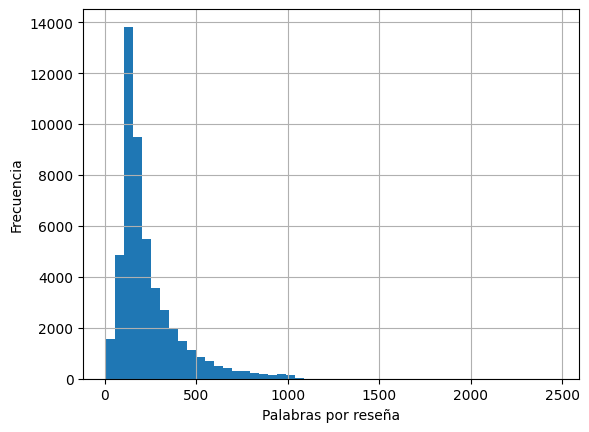

Con <br />: 29200


In [6]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, classification_report

# Balance de clases y tamaño de cada partición
#print(df.groupby(["split", "sentiment"]).size().unstack())

# Longitud de reseñas (en palabras)
df["n_palabras"] = df["review"].str.split().str.len()
print(df["n_palabras"].describe())

df["n_palabras"].hist(bins=50)
plt.xlabel("Palabras por reseña"); plt.ylabel("Frecuencia")
plt.show()

# ¿Cuántas reseñas tienen etiquetas HTML?
print("Con <br />:", df["review"].str.contains("<br", regex=False).sum())

In [7]:
# Encontrar los índices de las reseñas con menos y más palabras
idx_min = df['n_palabras'].idxmin()
idx_max = df['n_palabras'].idxmax()

print(f"=== RESEÑA CON MENOS PALABRAS ({df.loc[idx_min, 'n_palabras']} palabras) ===")
print(f"Sentiment: {'Positivo' if df.loc[idx_min, 'sentiment'] == 1 else 'Negativo'}")
print(df.loc[idx_min, 'review'])
print("\n" + "="*50 + "\n")

print(f"=== RESEÑA CON MÁS PALABRAS ({df.loc[idx_max, 'n_palabras']} palabras) ===")
print(f"Sentiment: {'Positivo' if df.loc[idx_max, 'sentiment'] == 1 else 'Negativo'}")
# Mostramos los primeros 1500 caracteres para no saturar la pantalla, pero se puede imprimir completa
print(df.loc[idx_max, 'review'][:1500] + '\n... [TRUNCADO]')


=== RESEÑA CON MENOS PALABRAS (4 palabras) ===
Sentiment: Negativo
Primary plot!Primary direction!Poor interpretation.


=== RESEÑA CON MÁS PALABRAS (2470 palabras) ===
Sentiment: Positivo
Match 1: Tag Team Table Match Bubba Ray and Spike Dudley vs Eddie Guerrero and Chris Benoit Bubba Ray and Spike Dudley started things off with a Tag Team Table Match against Eddie Guerrero and Chris Benoit. According to the rules of the match, both opponents have to go through tables in order to get the win. Benoit and Guerrero heated up early on by taking turns hammering first Spike and then Bubba Ray. A German suplex by Benoit to Bubba took the wind out of the Dudley brother. Spike tried to help his brother, but the referee restrained him while Benoit and Guerrero ganged up on him in the corner. With Benoit stomping away on Bubba, Guerrero set up a table outside. Spike dashed into the ring and somersaulted over the top rope onto Guerrero on the outside! After recovering and taking care of Spike, Gu

In [8]:
def limpiar(texto):
    texto = re.sub(r"<[^>]+>", " ", texto)      # quita etiquetas HTML
    texto = texto.lower()                        # minúsculas
    texto = re.sub(r"[^a-z' ]", " ", texto)      # quita puntuación, números y símbolos (conserva ')
    texto = re.sub(r"\s+", " ", texto).strip()   # colapsa espacios
    return texto

df["clean"] = df["review"].apply(limpiar)
print(df.loc[0, "review"][:200])
print(df.loc[0, "clean"][:200])

this was the most costly film, when produced. Sir Alexander Korda and H.G. Wells were both distressed by its poor ratings---for good reason. it was and remains far ahead of its time. aside from the se
this was the most costly film when produced sir alexander korda and h g wells were both distressed by its poor ratings for good reason it was and remains far ahead of its time aside from the seemingly


In [9]:
df.head()

,review,sentiment,split,n_palabras,clean
0,"this was the most costly film, when produced. ...",1,train,388,this was the most costly film when produced si...
1,I just went to a screening of the film during ...,1,train,270,i just went to a screening of the film during ...
2,Another Excellent Arnold movie. This futuristi...,1,train,70,another excellent arnold movie this futuristic...
3,"Inspector ""Dirty"" Harry Callahan once again an...",1,train,253,inspector dirty harry callahan once again ange...
4,Excellent writing and wild cast. The tech is p...,1,train,48,excellent writing and wild cast the tech is po...


In [10]:
train_full = df[df["split"] == "train"]
test = df[df["split"] == "test"]      # se queda intacto hasta el final

train, dev = train_test_split(
    train_full,
    test_size=0.2,
    stratify=train_full["sentiment"],
    random_state=42
)

print(len(train), len(dev), len(test))   # 20000, 5000, 25000

20000 5000 25000


In [11]:
vectorizer = CountVectorizer(
    ngram_range=(1,1),
    token_pattern=r"[a-z]+(?:'[a-z]+)*",   # conserva didn't, isn't...
    min_df=2
)
X_train = vectorizer.fit_transform(train["clean"])   # fit SOLO con train
X_dev   = vectorizer.transform(dev["clean"])
X_test  = vectorizer.transform(test["clean"])

y_train, y_dev, y_test = train["sentiment"], dev["sentiment"], test["sentiment"]
print("Vocabulario:", len(vectorizer.vocabulary_))

nb = MultinomialNB(alpha=1.0)
nb.fit(X_train, y_train)

Vocabulario: 42630


MultinomialNB()

In [12]:
print(X_train[:3])

<Compressed Sparse Row sparse matrix of dtype 'int64'
	with 440 stored elements and shape (3, 42630)>
  Coords	Values
  (0, 21910)	4
  (0, 0)	21
  (0, 22348)	2
  (0, 26361)	18
  (0, 33601)	4
  (0, 28280)	2
  (0, 9086)	3
  (0, 1287)	1
  (0, 26554)	1
  (0, 34148)	4
  (0, 24465)	1
  (0, 16099)	1
  (0, 28923)	3
  (0, 1248)	12
  (0, 34716)	1
  (0, 29365)	3
  (0, 13848)	1
  (0, 19760)	2
  (0, 27066)	2
  (0, 13569)	1
  (0, 25995)	3
  (0, 37907)	14
  (0, 38051)	5
  (0, 19685)	13
  (0, 40103)	1
  :	:
  (2, 16787)	3
  (2, 38030)	2
  (2, 41020)	1
  (2, 636)	1
  (2, 16286)	1
  (2, 41725)	1
  (2, 22390)	1
  (2, 8178)	2
  (2, 36214)	1
  (2, 21415)	1
  (2, 35019)	2
  (2, 16260)	1
  (2, 3214)	1
  (2, 33389)	2
  (2, 1038)	1
  (2, 9455)	2
  (2, 33378)	2
  (2, 629)	1
  (2, 38075)	1
  (2, 24963)	1
  (2, 5298)	1
  (2, 4223)	1
  (2, 12717)	1
  (2, 36985)	1
  (2, 30668)	1


In [13]:
# Tomamos el texto limpio de la primera fila del conjunto de train como ejemplo
ejemplo_texto = train["clean"].iloc[2]
ejemplo_vectorizado = X_train[2]

print("Texto original limpio:")
print(ejemplo_texto)
print("\n" + "="*50 + "\n")

print("Representación en la Matriz Dispersa (Sparse Matrix) - (Fila, ID_Vocabulario) Frecuencia:")
print(ejemplo_vectorizado)
print("\n" + "="*50 + "\n")

# Mapeamos los IDs de vuelta a las palabras correspondientes del vocabulario
print("Palabras presentes en este texto y sus frecuencias:")
nombres_caracteristicas = vectorizer.get_feature_names_out()
coordenadas = ejemplo_vectorizado.tocoo()
for col, val in zip(coordenadas.col, coordenadas.data):
    print(f"- '{nombres_caracteristicas[col]}' (ID: {col}): {val} vez/veces")


Texto original limpio:
this is an amazing movie and all of the actors and actresses and very good even though some of the actors and actresses weren't very popular in show business it seemed like they have been acting since they were one year old it was funny gross and just all out a very good movie in most parts i just didn't know what was going to happen next i was like i think this is going to happen wait i think this is going to happen all age groups will love this movie in some parts i couldn't stop laughing it was so funny but in some parts i was totally grossed out and i couldn't believe what i was seeing i am definitely going to see this movie again it is one of those movies where it can't get boring every time you see it is so suspenseful i definitely recommend seeing this movie


Representación en la Matriz Dispersa (Sparse Matrix) - (Fila, ID_Vocabulario) Frecuencia:
<Compressed Sparse Row sparse matrix of dtype 'int64'
	with 79 stored elements and shape (1, 42630)>
  Coords

In [14]:
def evaluar(modelo, X, y, nombre):
    pred = modelo.predict(X)
    proba = modelo.predict_proba(X)[:, 1]
    print(f"── {nombre} ──")
    print(f"Exactitud: {accuracy_score(y, pred):.4f}")
    print(f"F1:        {f1_score(y, pred):.4f}")
    print(f"AUC-ROC:   {roc_auc_score(y, proba):.4f}")
    return pred

pred_dev = evaluar(nb, X_dev, y_dev, "Dev")
print(classification_report(y_dev, pred_dev, target_names=["neg", "pos"]))

# Test: úsalo UNA sola vez, cuando el baseline esté definitivo
pred_test = evaluar(nb, X_test, y_test, "Test")

── Dev ──
Exactitud: 0.8500
F1:        0.8445
AUC-ROC:   0.9190
              precision    recall  f1-score   support

         neg       0.83      0.89      0.86      2500
         pos       0.88      0.81      0.84      2500

    accuracy                           0.85      5000
   macro avg       0.85      0.85      0.85      5000
weighted avg       0.85      0.85      0.85      5000

── Test ──
Exactitud: 0.8142
F1:        0.8016
AUC-ROC:   0.8911


In [15]:
# Seleccionamos una reseña del conjunto de desarrollo (por ejemplo, la primera)
indice_ejemplo = 0
texto_original = dev["review"].iloc[indice_ejemplo]
texto_limpio = dev["clean"].iloc[indice_ejemplo]
etiqueta_real = dev["sentiment"].iloc[indice_ejemplo]

# Transformamos el texto con el vectorizer para que tenga el formato adecuado
vector_ejemplo = X_dev[indice_ejemplo]

# Obtenemos las probabilidades de cada clase
probabilidades = nb.predict_proba(vector_ejemplo)[0]
prediccion = nb.predict(vector_ejemplo)[0]

print("=== TEXTO DE LA RESEÑA ===")
print(texto_original[:500] + ("..." if len(texto_original) > 500 else ""))
print("\n" + "="*30)
print(f"Etiqueta Real: {'Positivo (1)' if etiqueta_real == 1 else 'Negativo (0)'}")
print(f"Predicción del Modelo: {'Positivo (1)' if prediccion == 1 else 'Negativo (0)'}")
print("="*30)
print(f"Probabilidad de ser NEGATIVA (0): {probabilidades[0]:.6f} ({probabilidades[0]*100:.4f}%)")
print(f"Probabilidad de ser POSITIVA (1): {probabilidades[1]:.6f} ({probabilidades[1]*100:.4f}%)")


=== TEXTO DE LA RESEÑA ===
I hate over-long over-talky French movies, but my favorite movie of all time is the longest and talkiest French movie of them all. I saw it twice in the mid-70's, and then it disappeared. But I finally got to see it again in 1999, and fell in love all over again. What is most remarkable is that it feels every bit as fresh today as it did 25 years ago. If you haven't seen it, don't miss your chance!

Etiqueta Real: Positivo (1)
Predicción del Modelo: Positivo (1)
Probabilidad de ser NEGATIVA (0): 0.002384 (0.2384%)
Probabilidad de ser POSITIVA (1): 0.997616 (99.7616%)


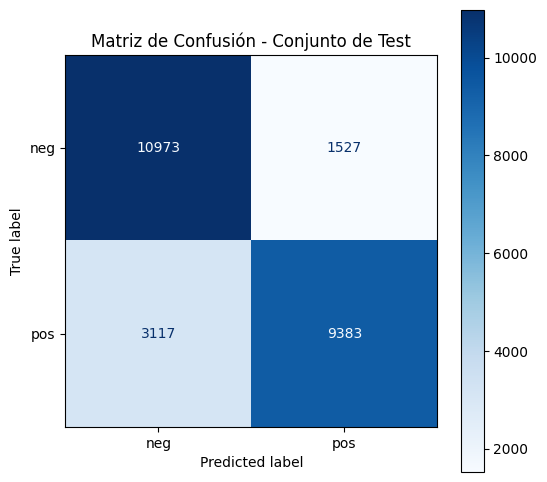

Verdaderos Negativos (TN): 10973
Falsos Positivos (FP): 1527
Falsos Negativos (FN): 3117
Verdaderos Positivos (TP): 9383


In [16]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Calcular la matriz de confusión usando las etiquetas reales de test (y_test) y las predicciones (pred_test)
cm = confusion_matrix(y_test, pred_test)

# Crear la visualización de la matriz de confusión
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["neg", "pos"])

# Graficar la matriz
fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(ax=ax, cmap=plt.cm.Blues, values_format='d')
plt.title("Matriz de Confusión - Conjunto de Test")
plt.show()

# Imprimir también los valores numéricos directos
tn, fp, fn, tp = cm.ravel()
print(f"Verdaderos Negativos (TN): {tn}")
print(f"Falsos Positivos (FP): {fp}")
print(f"Falsos Negativos (FN): {fn}")
print(f"Verdaderos Positivos (TP): {tp}")


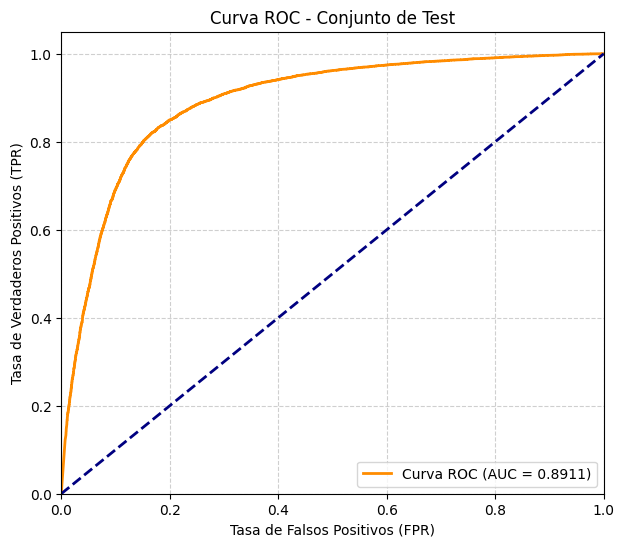

In [17]:
from sklearn.metrics import roc_curve, auc

proba_test = nb.predict_proba(X_test)[:, 1]

fpr, tpr, _ = roc_curve(y_test, proba_test)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'Curva ROC (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Tasa de Falsos Positivos (FPR)')
plt.ylabel('Tasa de Verdaderos Positivos (TPR)')
plt.title('Curva ROC - Conjunto de Test')
plt.legend(loc="lower right")
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()


### Etapa 2 - **Primera aproximación**. TF-IDF de unigramas y bigramas + regresión logística, con y sin marcado de negación

2.1 Modelo A: TF-IDF (unigramas + bigramas) + Regresión Logística, **sin** marcado de negación

In [18]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

# TF-IDF con unigramas y bigramas sobre el texto limpio de la Etapa 1
tfidf_A = TfidfVectorizer(
    ngram_range=(1, 2),
    token_pattern=r"[a-z]+(?:'[a-z]+)*",   # conserva didn't, isn't...
    min_df=2,
    sublinear_tf=True
)
XA_train = tfidf_A.fit_transform(train["clean"])   # fit SOLO con train
XA_dev   = tfidf_A.transform(dev["clean"])
XA_test  = tfidf_A.transform(test["clean"])
print("Vocabulario (uni+bigramas):", len(tfidf_A.vocabulary_))

# Elegimos C (regularización) con el conjunto Dev
mejor_C_A, mejor_auc_A = None, -1
for C in [0.1, 0.5, 1, 5, 10, 50, 70, 90]:
    m = LogisticRegression(C=C, max_iter=2000, solver="liblinear")
    m.fit(XA_train, y_train)
    auc_dev = roc_auc_score(y_dev, m.predict_proba(XA_dev)[:, 1])
    print(f"C={C:<5} AUC Dev = {auc_dev:.4f}")
    if auc_dev > mejor_auc_A:
        mejor_C_A, mejor_auc_A = C, auc_dev
print("Mejor C:", mejor_C_A)

lr_A = LogisticRegression(C=mejor_C_A, max_iter=2000, solver="liblinear")
lr_A.fit(XA_train, y_train)
pred_dev_A = evaluar(lr_A, XA_dev, y_dev, "Modelo A - Dev (sin negación)")
print(classification_report(y_dev, pred_dev_A, target_names=["neg", "pos"]))

Vocabulario (uni+bigramas): 362708
C=0.1   AUC Dev = 0.9393
C=0.5   AUC Dev = 0.9558
C=1     AUC Dev = 0.9604
C=5     AUC Dev = 0.9660
C=10    AUC Dev = 0.9668
C=50    AUC Dev = 0.9674
C=70    AUC Dev = 0.9674
C=90    AUC Dev = 0.9674
Mejor C: 90
── Modelo A - Dev (sin negación) ──
Exactitud: 0.9070
F1:        0.9070
AUC-ROC:   0.9674
              precision    recall  f1-score   support

         neg       0.91      0.91      0.91      2500
         pos       0.91      0.91      0.91      2500

    accuracy                           0.91      5000
   macro avg       0.91      0.91      0.91      5000
weighted avg       0.91      0.91      0.91      5000



### Interpretación del Modelo A

En esta etapa se utilizó TF-IDF con unigramas y bigramas para representar numéricamente las reseñas. Posteriormente, entrenamos una regresión logística para clasificarlas como positivas o negativas.

El uso de bigramas permite considerar pares de palabras consecutivas y capturar expresiones como "not good".

2.2 Marcado de negación

In [19]:
NEGACIONES = {"not", "no", "never", "none", "nobody", "nothing", "nowhere",
              "neither", "nor", "cannot", "without", "hardly", "barely", "scarcely"}
TOKEN_RE = re.compile(r"[a-z]+(?:'[a-z]+)*|[.,;:!?()]")   # palabras o signos de puntuación
PUNTUACION = set(".,;:!?()")

def es_negacion(tok):
    return tok in NEGACIONES or tok.endswith("n't")      # didn't, isn't, don't, can't...

def marcar_negacion(texto):
    texto = re.sub(r"<[^>]+>", " ", texto).lower()
    salida, en_negacion = [], False
    for tok in TOKEN_RE.findall(texto):
        if tok in PUNTUACION:                            # la puntuación cierra el alcance
            en_negacion = False
            continue                                     # y se descarta
        salida.append("NEG_" + tok if en_negacion else tok)
        if es_negacion(tok):                             # a partir de aquí, se marca
            en_negacion = True
    return " ".join(salida)

# Ejemplos para verificar la regla
ejemplos = [
    "This movie is not good, it was a waste.",
    "I didn't like the acting or the plot. Great music!",
    "Not bad at all<br />but never boring; fun",
]
for e in ejemplos:
    print("ORIGINAL:", e)
    print("MARCADO :", marcar_negacion(e), "\n")

df["clean_neg"] = df["review"].apply(marcar_negacion)
train = df.loc[train.index]; dev = df.loc[dev.index]; test = df.loc[test.index]   # mismas particiones, con la nueva columna
print(dev["clean_neg"].iloc[0][:300])

ORIGINAL: This movie is not good, it was a waste.
MARCADO : this movie is not NEG_good it was a waste 

ORIGINAL: I didn't like the acting or the plot. Great music!
MARCADO : i didn't NEG_like NEG_the NEG_acting NEG_or NEG_the NEG_plot great music 

ORIGINAL: Not bad at all<br />but never boring; fun
MARCADO : not NEG_bad NEG_at NEG_all NEG_but NEG_never NEG_boring fun 

i hate over long over talky french movies but my favorite movie of all time is the longest and talkiest french movie of them all i saw it twice in the mid s and then it disappeared but i finally got to see it again in and fell in love all over again what is most remarkable is that it feels every bit


### Marcado explícito de negación

La función identifica palabras de negación y marca los tokens siguientes con el prefijo `NEG_` hasta encontrar un signo de puntuación reconocido.

Esta transformación busca distinguir palabras como `good` y `NEG_good`.

2.3 Modelo B: TF-IDF (unigramas + bigramas) + Regresión Logística, **con** marcado de negación

In [20]:
tfidf_B = TfidfVectorizer(
    ngram_range=(1, 2),
    token_pattern=r"[A-Za-z_]+(?:'[a-z]+)*",   # acepta NEG_palabra
    lowercase=False,                            # ya está en minúsculas; así no se altera NEG_
    min_df=2,
    sublinear_tf=True
)
XB_train = tfidf_B.fit_transform(train["clean_neg"])   # fit SOLO con train
XB_dev   = tfidf_B.transform(dev["clean_neg"])
XB_test  = tfidf_B.transform(test["clean_neg"])
print("Vocabulario (uni+bigramas, con NEG_):", len(tfidf_B.vocabulary_))
mejor_C_B, mejor_auc_B = None, -1
for C in [0.1, 0.5, 1, 5, 10, 50, 70, 90]:
    m = LogisticRegression(C=C, max_iter=2000, solver="liblinear")
    m.fit(XB_train, y_train)
    auc_dev = roc_auc_score(y_dev, m.predict_proba(XB_dev)[:, 1])
    print(f"C={C:<5} AUC Dev = {auc_dev:.4f}")
    if auc_dev > mejor_auc_B:
        mejor_C_B, mejor_auc_B = C, auc_dev
print("Mejor C:", mejor_C_B)

lr_B = LogisticRegression(C=mejor_C_B, max_iter=2000, solver="liblinear")
lr_B.fit(XB_train, y_train)
pred_dev_B = evaluar(lr_B, XB_dev, y_dev, "Modelo B - Dev (con negación)")
print(classification_report(y_dev, pred_dev_B, target_names=["neg", "pos"]))

Vocabulario (uni+bigramas, con NEG_): 390940
C=0.1   AUC Dev = 0.9365
C=0.5   AUC Dev = 0.9561
C=1     AUC Dev = 0.9613
C=5     AUC Dev = 0.9672
C=10    AUC Dev = 0.9680
C=50    AUC Dev = 0.9685
C=70    AUC Dev = 0.9685
C=90    AUC Dev = 0.9685
Mejor C: 70
── Modelo B - Dev (con negación) ──
Exactitud: 0.9078
F1:        0.9079
AUC-ROC:   0.9685
              precision    recall  f1-score   support

         neg       0.91      0.91      0.91      2500
         pos       0.91      0.91      0.91      2500

    accuracy                           0.91      5000
   macro avg       0.91      0.91      0.91      5000
weighted avg       0.91      0.91      0.91      5000



In [21]:
print(XB_train[:3])

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 1132 stored elements and shape (3, 390940)>
  Coords	Values
  (0, 223761)	0.024668119413473712
  (0, 56802)	0.022619912513281087
  (0, 228041)	0.029367893898753952
  (0, 255241)	0.02165067237240793
  (0, 304189)	0.048406099644249696
  (0, 275374)	0.07033975750877486
  (0, 131244)	0.04821054394554449
  (0, 81899)	0.04982011089542634
  (0, 264620)	0.04296723210457487
  (0, 308663)	0.04243125723335613
  (0, 239098)	0.0374258716283928
  (0, 177253)	0.013687851759813166
  (0, 279230)	0.045977983821269164
  (0, 74480)	0.020164286417746934
  (0, 311583)	0.03519937004919793
  (0, 281620)	0.04846708093483765
  (0, 162049)	0.030207364740135516
  (0, 210939)	0.014795681330071338
  (0, 269114)	0.01835732816511666
  (0, 158437)	0.03273791138275998
  (0, 251965)	0.01783600345071264
  (0, 45826)	0.02315527448262035
  (0, 49439)	0.012920963214627582
  (0, 25079)	0.01564085226237726
  (0, 52494)	0.04154379389836187
  :	:
  (2, 195931)	0.0406

### Entrenamiento del Modelo B

Se aplica TF-IDF al texto con negaciones marcadas y se entrena una regresión logística. Se mantiene el mismo procedimiento de selección de C utilizado en el Modelo A para facilitar la comparación.

2.4 Comparación: Baseline vs Modelo A vs Modelo B

In [22]:
def metricas(modelo, X, y):
    pred = modelo.predict(X)
    proba = modelo.predict_proba(X)[:, 1]
    return {"Exactitud": accuracy_score(y, pred),
            "F1": f1_score(y, pred),
            "AUC-ROC": roc_auc_score(y, proba)}

resultados = {
    "Baseline: BoW + Naive Bayes":         (metricas(nb,   X_dev,  y_dev), metricas(nb,   X_test,  y_test)),
    "A: TF-IDF 1-2g + LR (sin negación)":  (metricas(lr_A, XA_dev, y_dev), metricas(lr_A, XA_test, y_test)),
    "B: TF-IDF 1-2g + LR (con negación)":  (metricas(lr_B, XB_dev, y_dev), metricas(lr_B, XB_test, y_test)),
}

filas = []
for nombre, (m_dev, m_test) in resultados.items():
    fila = {"Modelo": nombre}
    fila.update({f"Dev {k}": v for k, v in m_dev.items()})
    fila.update({f"Test {k}": v for k, v in m_test.items()})
    filas.append(fila)

tabla = pd.DataFrame(filas).set_index("Modelo").round(4)
display(tabla)

# Efecto del marcado de negación (B - A) en Test
print("\nMejora por marcado de negación (B - A) en Test:")
for k in ["Exactitud", "F1", "AUC-ROC"]:
    d = resultados["B: TF-IDF 1-2g + LR (con negación)"][1][k] - resultados["A: TF-IDF 1-2g + LR (sin negación)"][1][k]
    print(f"  {k:<10}: {d:+.4f}")

,Dev Exactitud,Dev F1,Dev AUC-ROC,Test Exactitud,Test F1,Test AUC-ROC
Modelo,,,,,,
Baseline: BoW + Naive Bayes,0.8500,0.8445,0.9190,0.8142,0.8016,0.8911
A: TF-IDF 1-2g + LR (sin negación),0.9070,0.9070,0.9674,0.9034,0.9033,0.9651
B: TF-IDF 1-2g + LR (con negación),0.9078,0.9079,0.9685,0.9052,0.9051,0.9660



Mejora por marcado de negación (B - A) en Test:
  Exactitud : +0.0018
  F1        : +0.0018
  AUC-ROC   : +0.0008


### Interpretación de resultados

El Modelo A y el Modelo B superan al baseline en las métricas evaluadas. El Modelo B obtiene una mejora pequeña respecto al Modelo A en exactitud, F1 y AUC-ROC.

Estos resultados sugieren que el marcado explícito de negación aporta una mejora adicional en este conjunto de datos.

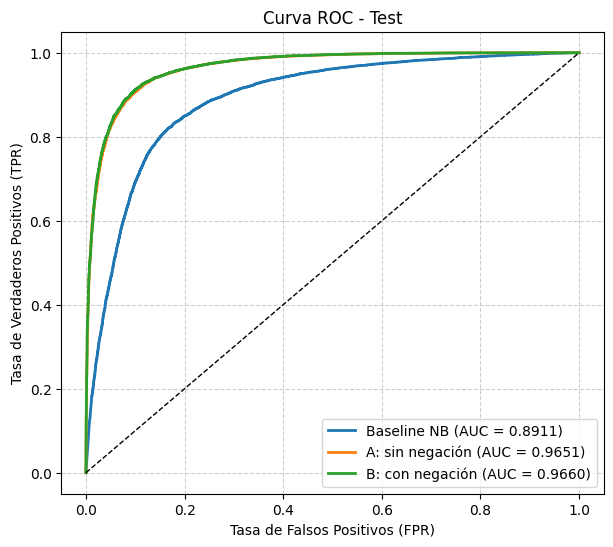

In [23]:
plt.figure(figsize=(7, 6))
for nombre, modelo, X in [("Baseline NB", nb, X_test),
                          ("A: sin negación", lr_A, XA_test),
                          ("B: con negación", lr_B, XB_test)]:
    fpr, tpr, _ = roc_curve(y_test, modelo.predict_proba(X)[:, 1])
    plt.plot(fpr, tpr, lw=2, label=f"{nombre} (AUC = {auc(fpr, tpr):.4f})")
plt.plot([0, 1], [0, 1], "k--", lw=1)
plt.xlabel("Tasa de Falsos Positivos (FPR)"); plt.ylabel("Tasa de Verdaderos Positivos (TPR)")
plt.title("Curva ROC - Test"); plt.legend(loc="lower right"); plt.grid(True, linestyle="--", alpha=0.6)
plt.show()

### Curva ROC

Se compara la tasa de verdaderos positivos con la tasa de falsos positivos para distintos umbrales. El AUC resume la capacidad de discriminación de cada modelo.

El Modelo B presenta el AUC más alto, aunque la diferencia respecto al Modelo A es pequeña.

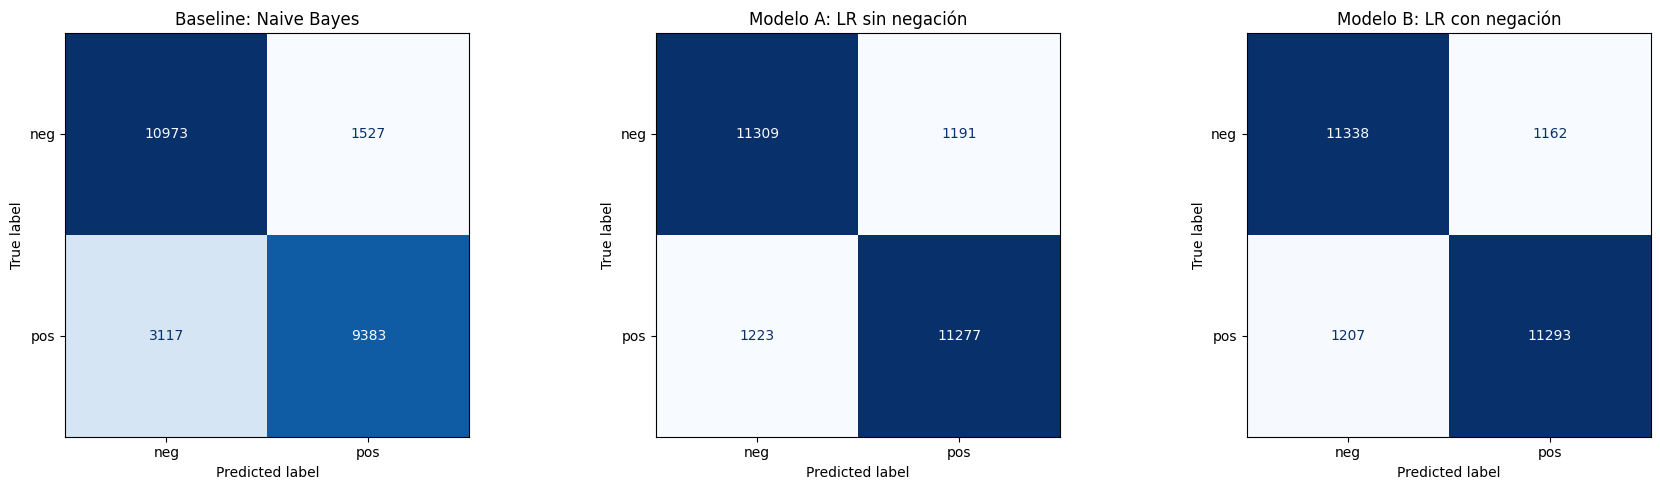

=== Baseline Naive Bayes ===
  Verdaderos Negativos (TN): 10973  | Falsos Positivos (FP): 1527
  Falsos Negativos (FN): 3117   | Verdaderos Positivos (TP): 9383

=== Modelo A (sin negación) ===
  Verdaderos Negativos (TN): 11309  | Falsos Positivos (FP): 1191
  Falsos Negativos (FN): 1223   | Verdaderos Positivos (TP): 11277

=== Modelo B (con negación) ===
  Verdaderos Negativos (TN): 11338  | Falsos Positivos (FP): 1162
  Falsos Negativos (FN): 1207   | Verdaderos Positivos (TP): 11293



In [24]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Calcular las predicciones en el conjunto de test para cada modelo
pred_test_nb = nb.predict(X_test)
pred_test_A = lr_A.predict(XA_test)
pred_test_B = lr_B.predict(XB_test)

# Obtener las matrices de confusión
cm_nb = confusion_matrix(y_test, pred_test_nb)
cm_A = confusion_matrix(y_test, pred_test_A)
cm_B = confusion_matrix(y_test, pred_test_B)

# Configurar la visualización en paralelo (1 fila, 3 columnas)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Baseline Naive Bayes
disp_nb = ConfusionMatrixDisplay(confusion_matrix=cm_nb, display_labels=["neg", "pos"])
disp_nb.plot(ax=axes[0], cmap=plt.cm.Blues, values_format='d', colorbar=False)
axes[0].set_title("Baseline: Naive Bayes")

# 2. Modelo A: TF-IDF (sin negación)
disp_A = ConfusionMatrixDisplay(confusion_matrix=cm_A, display_labels=["neg", "pos"])
disp_A.plot(ax=axes[1], cmap=plt.cm.Blues, values_format='d', colorbar=False)
axes[1].set_title("Modelo A: LR sin negación")

# 3. Modelo B: TF-IDF (con negación)
disp_B = ConfusionMatrixDisplay(confusion_matrix=cm_B, display_labels=["neg", "pos"])
disp_B.plot(ax=axes[2], cmap=plt.cm.Blues, values_format='d', colorbar=False)
axes[2].set_title("Modelo B: LR con negación")

plt.tight_layout()
plt.show()

# Imprimir métricas de soporte en texto
for nombre, cm in [("Baseline Naive Bayes", cm_nb), ("Modelo A (sin negación)", cm_A), ("Modelo B (con negación)", cm_B)]:
    tn, fp, fn, tp = cm.ravel()
    print(f"=== {nombre} ===")
    print(f"  Verdaderos Negativos (TN): {tn:<6} | Falsos Positivos (FP): {fp}")
    print(f"  Falsos Negativos (FN): {fn:<6} | Verdaderos Positivos (TP): {tp}\n")